# Prédiction de la résistance à la compression du béton

## Objectif
Ce notebook cherche à **prédire la résistance à la compression du béton (`Compressive_Strength`, en MPa)** à partir de la composition du mélange et de son âge. Cette résistance se mesure normalement en écrasant une éprouvette en laboratoire : un modèle fiable permettrait d'estimer la résistance d'une formulation avant de la couler.

Quatre modèles de régression sont entraînés puis comparés :

1. **Régression linéaire** (modèle de référence)
2. **Régression polynomiale** régularisée (Ridge)
3. **Random Forest** (forêt d'arbres de décision)
4. **MLP** (réseau de neurones multicouche)

## Jeu de données
Fichier : `data/Concrete_Data.csv` – 1 030 mélanges, 9 colonnes numériques, aucune valeur manquante, 25 lignes en double.

Les sept premières colonnes sont des quantités en **kg par m³ de béton**.

| Colonne | Unité | Description |
|---|---|---|
| `Cement` | kg/m³ | Ciment, le liant principal (102 à 540) |
| `Blast_Furnace_Slag` | kg/m³ | Laitier de haut fourneau, liant qui remplace une partie du ciment (0 à 359) |
| `Fly_Ash` | kg/m³ | Cendres volantes, autre liant de substitution (0 à 200) |
| `Water` | kg/m³ | Eau de gâchage (122 à 247) |
| `Superplasticizer` | kg/m³ | Superplastifiant : adjuvant qui fluidifie le béton et permet de réduire l'eau (0 à 32) |
| `Coarse_Aggregate` | kg/m³ | Gros granulats, gravier (801 à 1 145) |
| `Fine_Aggregate` | kg/m³ | Granulats fins, sable (594 à 993) |
| `Age` | jours | Âge du béton au moment de l'essai (1 à 365) |
| `Compressive_Strength` | MPa | **Variable cible** : résistance à la compression (2,3 à 82,6) |

Une variable est ajoutée pendant l'analyse : le **rapport eau / ciment** `W_C`.

## Sommaire
1. Installation des dépendances
2. Chargement des données
3. Exploration des données (doublons, rapport eau / ciment)
4. Visualisation des relations
5. Séparation entraînement / test
6. Modèle 1 : Régression linéaire
7. Modèle 2 : Régression polynomiale
8. Modèle 3 : Random Forest (et importance des variables)
9. Modèle 4 : Réseau de neurones (MLP)
10. Comparaison et conclusion

---
## 1. Installation des dépendances
Toutes les bibliothèques sont installées en une seule cellule : `pandas`, `scikit-learn`, `seaborn`, `matplotlib`, `numpy`. Elle n'est à exécuter qu'une fois par environnement.

In [ ]:
%pip install pandas scikit-learn  seaborn matplotlib numpy;

## 2. Chargement des données
On lit le fichier CSV dans un `DataFrame` pandas et on affiche les premières lignes pour vérifier la structure.

Les deux premières lignes ne diffèrent que par 15 kg/m³ de gros granulats (1 040 contre 1 055), au même âge de 28 jours, et pourtant leurs résistances sont très différentes (80,0 et 61,9 MPa). Les mesures de laboratoire sont donc assez **bruitées** : aucun modèle ne pourra prédire parfaitement la résistance.

In [1]:
import pandas as pd

df = pd.read_csv('data/Concrete_Data.csv')
df.head()


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## 3. Exploration des données
Trois vérifications rapides :
- `info()` : types des colonnes et nombre de valeurs non nulles. Toutes les colonnes sont numériques : **aucun encodage n'est nécessaire** ;
- `describe()` : statistiques descriptives ;
- `isna().sum()` : nombre de valeurs manquantes par colonne (**aucune** ici).

**Observations :**
- Les échelles sont très différentes : de 0 à 32 kg/m³ pour le superplastifiant, contre ~1 000 kg/m³ pour les gros granulats. Une **normalisation** est indispensable pour les modèles sensibles à l'échelle (régression polynomiale régularisée, MLP). Elle est inutile pour la Random Forest.
- `Age` est très asymétrique : médiane de 28 jours, mais un maximum de 365 jours.
- `Blast_Furnace_Slag`, `Fly_Ash` et `Superplasticizer` valent souvent **0** (médiane nulle pour `Fly_Ash`). Ce ne sont **pas des valeurs manquantes** : 0 signifie que l'ingrédient n'est pas utilisé dans ce mélange. Il ne faut donc pas les remplacer.
- La cible varie de 2,3 à 82,6 MPa, avec une moyenne de 35,8 MPa, proche de la médiane (34,4 MPa) : sa distribution est à peu près symétrique.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Cement                1030 non-null   float64
 1   Blast_Furnace_Slag    1030 non-null   float64
 2   Fly_Ash               1030 non-null   float64
 3   Water                 1030 non-null   float64
 4   Superplasticizer      1030 non-null   float64
 5   Coarse_Aggregate      1030 non-null   float64
 6   Fine_Aggregate        1030 non-null   float64
 7   Age                   1030 non-null   int64  
 8   Compressive_Strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Blast_Furnace_Slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Fly_Ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Coarse_Aggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Fine_Aggregate,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
Compressive_Strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


In [4]:
df.isna().sum()

Cement                  0
Blast_Furnace_Slag      0
Fly_Ash                 0
Water                   0
Superplasticizer        0
Coarse_Aggregate        0
Fine_Aggregate          0
Age                     0
Compressive_Strength    0
dtype: int64

### Doublons
`duplicated()` détecte **25 lignes strictement identiques** (même composition, même âge, même résistance). On les affiche, puis on les supprime avec `drop_duplicates()` ; `reset_index(drop=True)` renumérote les lignes de 0 à 1 004.

- `keep=False` marque **toutes** les copies d'une ligne en double (et pas seulement les répétitions), et le tri place les copies côte à côte.
- `display(...)` est nécessaire pour afficher ce tableau : dans une cellule Jupyter, seule la **dernière** expression est affichée automatiquement.

Il faut supprimer les doublons **avant** la séparation train / test. Sinon, une copie d'une ligne peut se retrouver dans l'entraînement et l'autre dans le test : le modèle serait évalué sur des données qu'il a déjà vues, et le score de test serait trop optimiste.

Résultat : 1 030 → **1 005 lignes**, 9 colonnes.

In [5]:
print('Doublons :', df.duplicated().sum())

# Toutes les copies des lignes en double, triées pour voir les paires côte à côte
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)))

df = df.drop_duplicates().reset_index(drop=True)
print('Après suppression :', df.shape)

Doublons : 25


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


Après suppression : (1005, 9)


### Variable construite : rapport eau / ciment
On crée le **rapport eau / ciment** `W_C = Water / Cement`. En génie civil, c'est le paramètre le plus connu de la résistance du béton (loi d'Abrams) : **moins il y a d'eau par kilo de ciment, plus le béton est résistant**. `Cement` ne vaut jamais 0 (minimum 102 kg/m³), la division est donc toujours possible.

Le rapport varie de 0,27 à 1,88 (médiane 0,69).

La colonne est créée **juste après la suppression des doublons**, avant les visualisations et avant la définition de `X`. Ainsi, une exécution complète du notebook de haut en bas (*Restart & Run All*) donne toujours le même résultat, et `W_C` fait bien partie des variables explicatives de tous les modèles. Toute nouvelle variable construite devra être ajoutée au même endroit.

In [6]:
df['W_C'] = df['Water'] / df['Cement']
df['W_C'].describe().round(2)

count    1005.00
mean        0.76
std         0.31
min         0.27
25%         0.55
50%         0.69
75%         0.94
max         1.88
Name: W_C, dtype: float64

## 4. Visualisation des relations

### Résistance vs chaque ingrédient
Un nuage de points par variable explicative, avec l'ingrédient en abscisse et la résistance (la cible) en **ordonnée** : chaque graphique se lit comme « la résistance en fonction de l'ingrédient ».

**Lecture** (corrélation de Pearson avec la résistance) :

| Variable | Corrélation | Lecture |
|---|---|---|
| `Cement` | **+0,49** | plus de ciment → béton plus résistant ; la relation la plus nette |
| `Superplasticizer` | +0,34 | effet positif, mais beaucoup de mélanges n'en contiennent pas (bande verticale à 0) |
| `Age` | +0,34 | effet positif mais non linéaire (voir le diagramme en boîtes plus bas) |
| `Water` | −0,27 | trop d'eau affaiblit le béton |
| `Fine_Aggregate` | −0,19 | effet faible |
| `Coarse_Aggregate` | −0,14 | effet faible |
| `Blast_Furnace_Slag` | +0,10 | effet faible, nombreuses valeurs à 0 |
| `Fly_Ash` | −0,08 | effet quasi nul pris isolément, nombreuses valeurs à 0 |

Aucune variable n'explique seule la résistance : le nuage est toujours très dispersé. C'est la **combinaison** des ingrédients, et l'âge, qui compte.

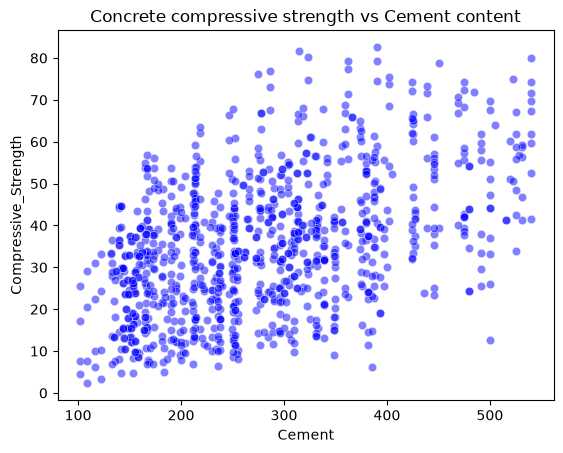

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x="Cement", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Cement content")
plt.show()

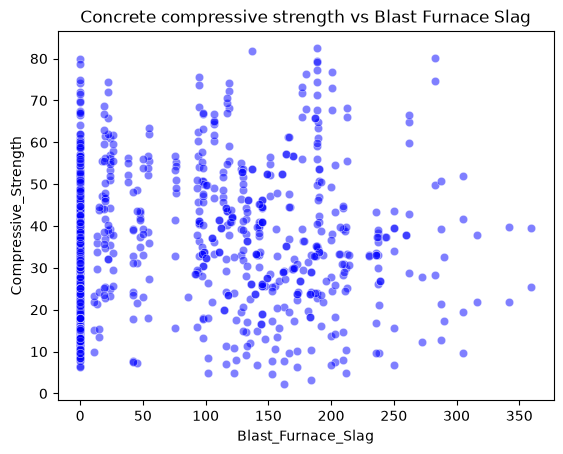

In [8]:
sns.scatterplot(data=df, x="Blast_Furnace_Slag", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Blast Furnace Slag")
plt.show()

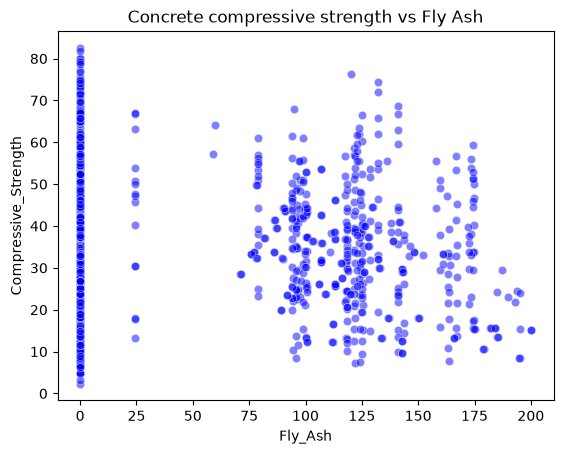

In [9]:
sns.scatterplot(data=df, x="Fly_Ash", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Fly Ash")
plt.show()

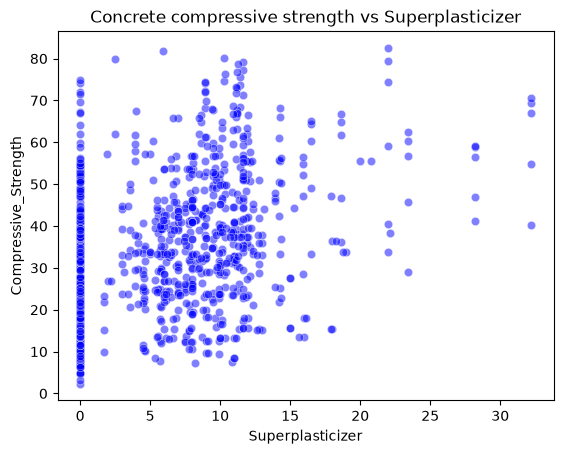

In [10]:
sns.scatterplot(data=df, x="Superplasticizer", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Superplasticizer")
plt.show()

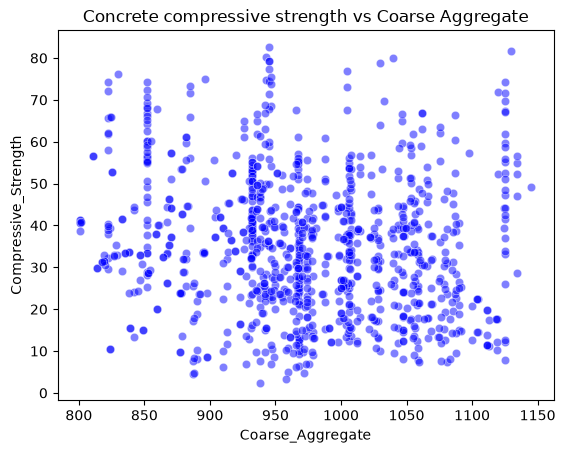

In [11]:
sns.scatterplot(data=df, x="Coarse_Aggregate", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Coarse Aggregate")
plt.show()

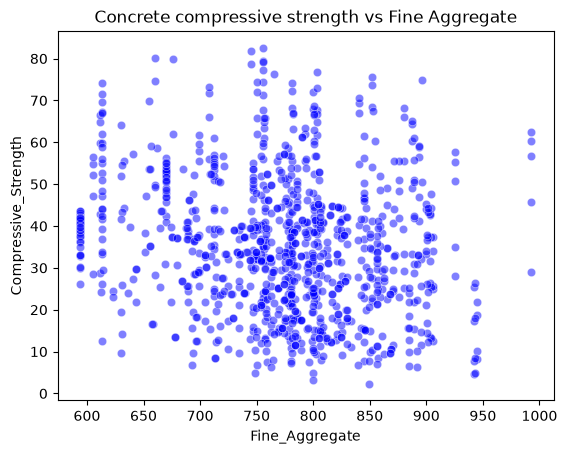

In [12]:
sns.scatterplot(data=df, x="Fine_Aggregate", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Fine Aggregate")
plt.show()

### Âge vs résistance
`Age` ne prend qu'une quinzaine de valeurs distinctes (1, 3, 7, 14, 28, 56, 90, 91, 100, 120, 180, 270, 360, 365 jours) : ce sont les échéances d'essai normalisées en laboratoire. Le nuage forme donc des colonnes verticales.

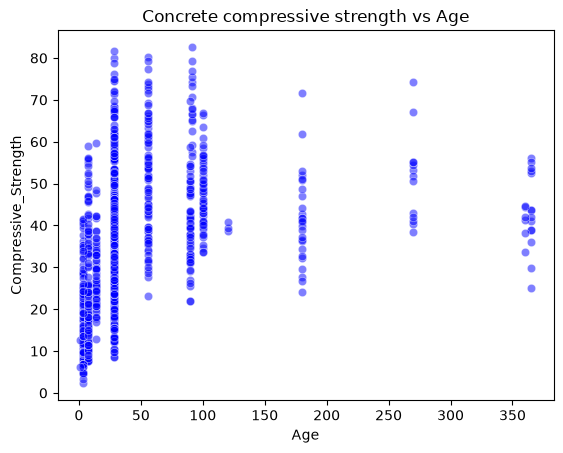

In [13]:
sns.scatterplot(data=df, x="Age", y="Compressive_Strength", color="blue", alpha=0.5)
plt.title("Concrete compressive strength vs Age")
plt.show()

### Variables explicatives, cible et corrélations
- `y` : la variable cible `Compressive_Strength` ;
- `X` : toutes les autres colonnes, soit **9 variables explicatives** (les 8 colonnes d'origine et `W_C`).

La carte de chaleur affiche la corrélation de Pearson entre chaque paire de colonnes de `df` (de −1 à 1), **cible comprise**. Elle sert à deux choses :
1. la ligne `Compressive_Strength` montre quelles variables sont le plus liées à la résistance ;
2. le reste du tableau permet de repérer une éventuelle **multicolinéarité** (variables explicatives très corrélées entre elles), qui rend les coefficients de la régression linéaire instables et difficiles à interpréter.

`center=0` centre l'échelle de couleurs sur 0 : bleu = corrélation négative, rouge = positive, blanc = pas de lien linéaire.

**Lecture – lien avec la résistance :**
- `Cement` (+0,49) et `W_C` (−0,49) sont les deux variables les plus liées à la résistance, devant `Age` et `Superplasticizer` (+0,34 chacune) et `Water` (−0,27).

**Lecture – corrélations entre variables explicatives :**
- `Cement` / `W_C` ≈ **−0,88** : ces deux variables portent presque la même information, ce qui est attendu puisque `W_C` est calculée à partir de `Cement`.
- `Water` / `Superplasticizer` ≈ −0,65 : c'est le rôle du superplastifiant, qui permet de réduire la quantité d'eau à fluidité égale.
- `Water` / `Fine_Aggregate` ≈ −0,44, `Fly_Ash` / `Superplasticizer` ≈ +0,41, `Cement` / `Fly_Ash` ≈ −0,39 : les cendres volantes remplacent une partie du ciment.

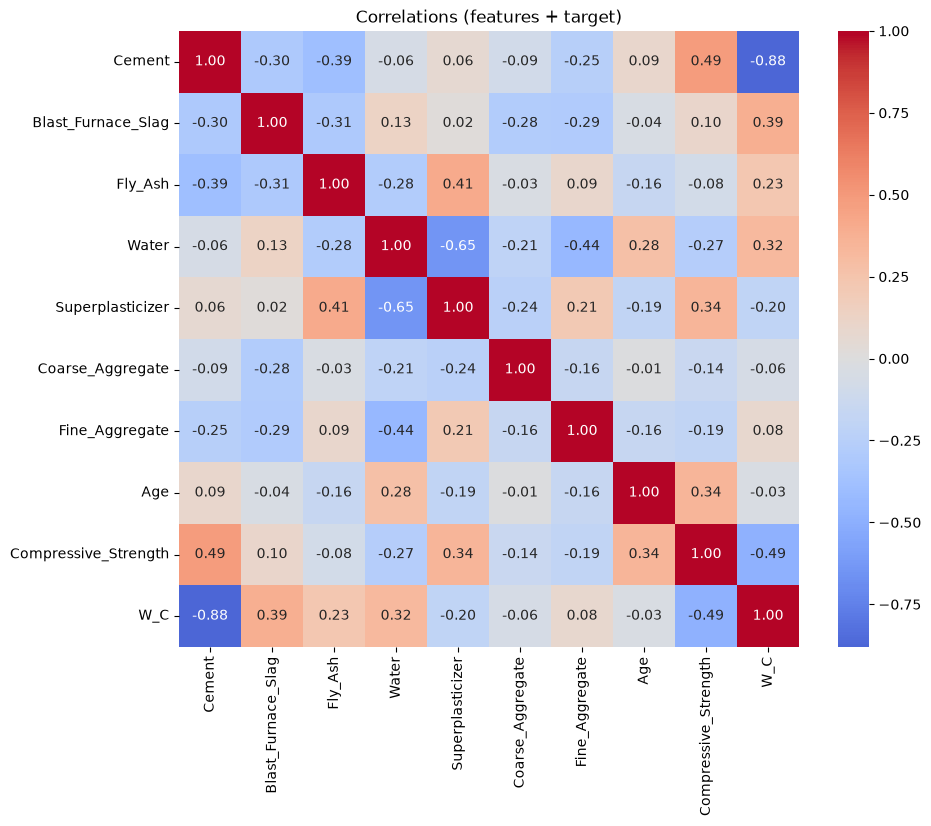

In [14]:
y = df['Compressive_Strength']
X = df.drop(columns=['Compressive_Strength'])

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr().round(2), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title("Correlations (features + target)")
plt.show()

### Résistance selon l'âge (diagramme en boîtes)
Une boîte par âge d'essai : la ligne centrale est la médiane, la boîte contient la moitié centrale des mélanges.

**Lecture** (médiane de la résistance) :

| Âge (jours) | 3 | 7 | 14 | 28 | 56 | 90 | 100 | 180 | 365 |
|---|---|---|---|---|---|---|---|---|---|
| Résistance médiane (MPa) | 15,5 | 21,2 | 26,5 | 33,7 | 51,1 | 39,7 | 47,0 | 40,9 | 42,8 |

- La résistance **augmente rapidement pendant les 28 premiers jours**, puis se stabilise : c'est la prise et le durcissement du béton. L'effet de l'âge est donc **non linéaire**, ce qu'une régression linéaire ne peut pas représenter (elle suppose un gain constant par jour).
- Au-delà de 56 jours, les médianes ne suivent plus l'âge : les mélanges testés à ces âges ne sont pas les mêmes, et la composition joue alors davantage que l'âge.
- Certains âges ont très peu de mesures (2 mélanges à 1 jour, 3 à 120 jours, 6 à 360 jours) : leurs boîtes sont peu fiables.
- 28 jours est l'échéance de référence (419 mélanges sur 1 005).

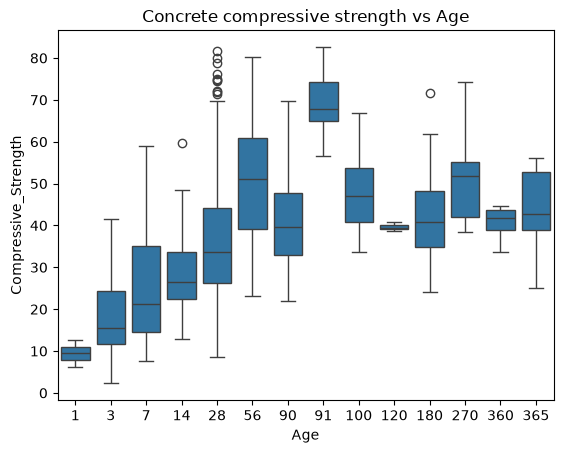

In [15]:
sns.boxplot(x="Age", y="Compressive_Strength", data=df)
plt.title("Concrete compressive strength vs Age")
plt.show()

### Résistance vs rapport eau / ciment
Nuage de points de la résistance en fonction de `W_C`, coloré selon l'âge (`hue="Age"`).

**Lecture :**
- La résistance baisse nettement quand le rapport augmente (corrélation ≈ **−0,49**, aussi forte que celle du ciment seul) : c'est la loi d'Abrams.
- À rapport égal, les bétons jeunes (couleurs foncées) sont moins résistants : l'âge et le rapport eau / ciment agissent **ensemble**, ce qui justifie des modèles capables de représenter des interactions.

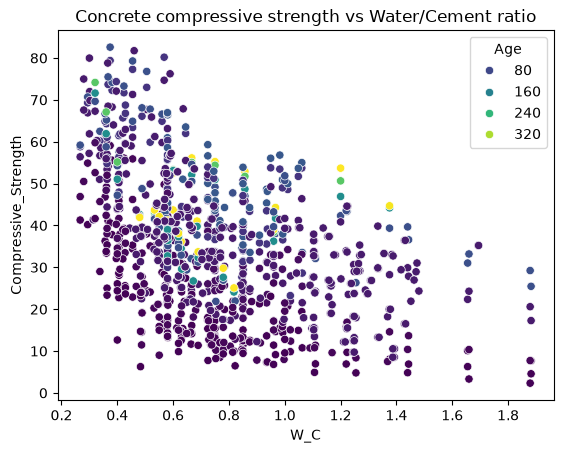

In [16]:
sns.scatterplot(x="W_C", y="Compressive_Strength", hue="Age", data=df, palette="viridis")
plt.title("Concrete compressive strength vs Water/Cement ratio")
plt.show()

### Distribution de chaque variable
Un histogramme par colonne, y compris `W_C`.

**Lecture :**
- `Blast_Furnace_Slag`, `Fly_Ash` et `Superplasticizer` présentent un grand pic à 0 (respectivement 465, 541 et 378 mélanges sur 1 005, soit 46 %, 54 % et 38 %). Ces distributions sont dites « gonflées en zéro » : il y a en fait deux familles de mélanges, avec et sans l'ingrédient.
- `Age` est concentré sur quelques valeurs, avec une longue traîne vers 365 jours. La transformation `np.log1p(Age)`, utilisée par la régression polynomiale et le MLP, rend sa relation avec la résistance plus proche d'une droite.
- `W_C` est légèrement étalée vers la droite (0,27 à 1,88).
- `Compressive_Strength` a une distribution à peu près en cloche : aucune transformation de la cible n'est nécessaire.

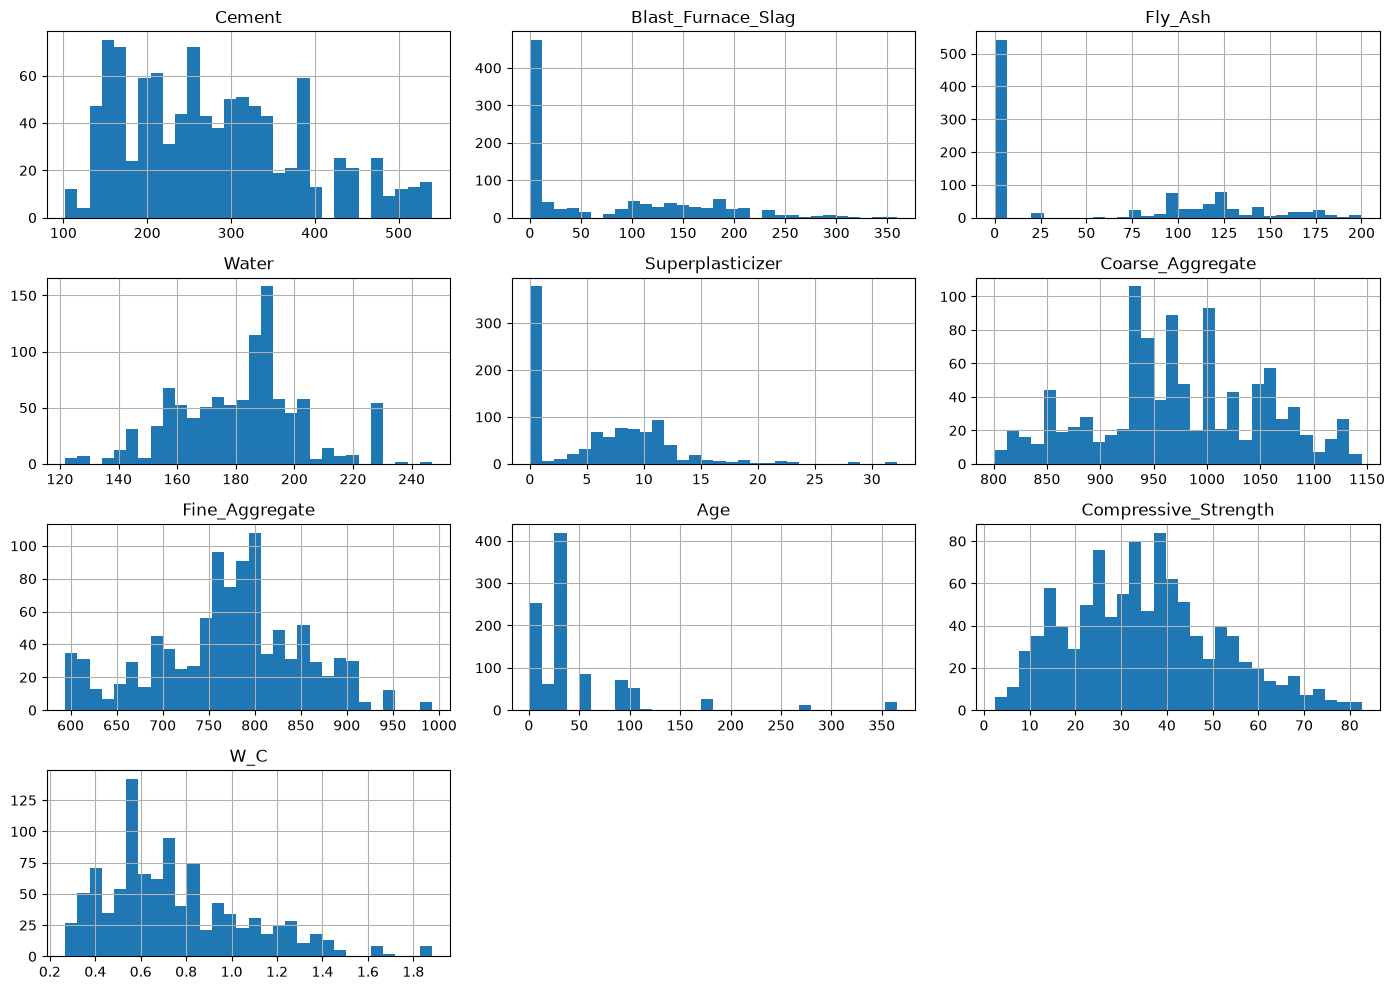

In [17]:
df.hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

## 5. Séparation entraînement / test
Les données sont découpées en :
- **80 % pour l'entraînement** (`x_train`, `y_train`, 804 mélanges) : utilisé pour ajuster les modèles ;
- **20 % pour le test** (`x_test`, `y_test`, 201 mélanges) : données jamais vues, utilisées pour mesurer la capacité de généralisation.

`random_state=42` fixe le tirage aléatoire pour que les résultats soient reproductibles. Les quatre modèles utilisent exactement le même découpage, ce qui rend leurs scores comparables.

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 6. Modèle 1 : Régression linéaire
La régression linéaire modélise la cible comme une combinaison linéaire des variables :

$$\hat{y} = \beta_0 + \beta_1 \cdot Cement + \beta_2 \cdot Slag + \beta_3 \cdot FlyAsh + \beta_4 \cdot Water + \beta_5 \cdot SP + \beta_6 \cdot Coarse + \beta_7 \cdot Fine + \beta_8 \cdot Age + \beta_9 \cdot W\_C$$

- `model.intercept_` : l'ordonnée à l'origine $\beta_0$ (≈ −18,26) ;
- `model.coef_` : les 9 coefficients, dans l'ordre des colonnes de `X`.

**Interprétation des coefficients obtenus** (toutes choses égales par ailleurs) :

| Variable | Coefficient | Lecture |
|---|---|---|
| `Cement` | ≈ +0,10 | +0,10 MPa par kg de ciment, soit +10 MPa pour 100 kg/m³ |
| `Blast_Furnace_Slag` | ≈ +0,10 | effet comparable au ciment, kilo pour kilo |
| `Fly_Ash` | ≈ +0,09 | idem, légèrement plus faible |
| `Water` | ≈ −0,11 | −0,11 MPa par kg d'eau supplémentaire |
| `Superplasticizer` | ≈ **+0,33** | l'effet le plus fort par kilo, mais les doses sont faibles (0 à 32 kg/m³) |
| `Coarse_Aggregate` | ≈ +0,01 | effet négligeable |
| `Fine_Aggregate` | ≈ +0,02 | effet négligeable |
| `Age` | ≈ +0,11 | +0,11 MPa par jour, **sur toute la plage de 1 à 365 jours** : irréaliste, puisque la résistance plafonne après ~56 jours |
| `W_C` | ≈ −5,82 | −0,58 MPa quand le rapport eau / ciment augmente de 0,1 |

- Les coefficients se comparent mal entre eux, car les variables n'ont pas la même échelle. Pour les comparer, il faudrait normaliser `X` au préalable.
- `Cement` et `W_C` sont très corrélés (≈ −0,88) : le modèle répartit leur effet commun entre les deux, de manière peu stable.

> 💡 Pour afficher chaque coefficient en face du nom de sa variable : `pd.Series(model.coef_, index=X.columns)`.

In [19]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()


model.fit(x_train, y_train)

print(model.intercept_.round(2))
print(model.coef_.round(2))

-18.26
[ 0.1   0.1   0.09 -0.11  0.33  0.01  0.02  0.11 -5.82]


### Prédictions
On compare les valeurs réelles et prédites sur les 10 premières lignes, d'abord sur le jeu d'entraînement, puis sur le jeu de test. Les écarts dépassent souvent 10 MPa (par exemple 25,4 MPa réels contre 45,6 MPa prédits pour la ligne 529 du test).

In [20]:
predicted = model.predict(x_train)
print(pd.DataFrame({'Actual': y_train, 'Predicted': predicted}).head(10).round(2))

     Actual  Predicted
78    41.30      59.64
29    38.60      29.22
280   23.14      34.01
507   23.85      29.77
652   15.75      23.81
946   44.52      49.23
289   52.04      43.63
165   10.38      20.43
761   16.26      23.32
497   24.13      32.48


In [21]:
predicted_test = model.predict(x_test)
print(pd.DataFrame({'Actual': y_test, 'Predicted': predicted_test}).head(10).round(2))

     Actual  Predicted
926   19.01      22.91
630   24.29      14.38
682   26.32      21.68
514   34.57      36.65
365   44.13      41.81
655   33.00      22.51
656   17.28      11.06
529   25.42      45.63
321   33.73      33.66
70    34.40      50.52


### Évaluation
Trois métriques sont calculées sur l'entraînement et sur le test :
- **MAE** (*Mean Absolute Error*) : erreur absolue moyenne, en MPa. Plus elle est faible, mieux c'est.
- **MSE** (*Mean Squared Error*) : moyenne des erreurs au carré. Elle pénalise davantage les grosses erreurs (unité : MPa²).
- **R²** (coefficient de détermination) : part de la variance de la résistance expliquée par le modèle (1 = parfait, 0 = pas mieux que prédire la moyenne).

Comparer train et test permet de détecter un **surapprentissage** (bon score en train, mauvais en test).

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('---------------- Train dataset -----------------------')
print('MAE train:', mean_absolute_error(y_train, predicted).__round__(2))
print('MSE train:', mean_squared_error(y_train, predicted).__round__(2))
print('R-Squared train:', r2_score(y_train, predicted).__round__(2))

print('---------------- Test dataset -----------------------')
print('MAE test:', mean_absolute_error(y_test, predicted_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predicted_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predicted_test).__round__(2))

---------------- Train dataset -----------------------
MAE train: 7.88
MSE train: 99.59
R-Squared train: 0.61
---------------- Test dataset -----------------------
MAE test: 8.83
MSE test: 123.86
R-Squared test: 0.58


**Résultats :** R² ≈ 0,61 (train) et 0,58 (test), MAE test ≈ 8,8 MPa, soit environ 25 % de la résistance moyenne (35,8 MPa).
- Les scores sont proches entre train et test : **pas de surapprentissage**.
- En revanche le modèle **sous-apprend** : il n'explique qu'un peu plus de la moitié de la variance. Il ne peut pas représenter le plafonnement de la résistance avec l'âge, ni les interactions entre ingrédients (par exemple âge × rapport eau / ciment).

### Valeurs réelles vs prédites (jeu de test)
Chaque point est un mélange du **jeu de test**. La droite rouge en pointillés représente une prédiction parfaite : plus les points en sont proches, meilleur est le modèle.

Le nuage est large autour de la droite, et l'erreur n'est pas répartie au hasard :
- pour le quart des bétons les plus faibles (< 24 MPa, souvent jeunes), le modèle **surestime** la résistance de ≈ 8 MPa en moyenne ;
- pour le quart des plus résistants (> 47 MPa), il la **sous-estime** de ≈ 12 MPa en moyenne.

Les prédictions sont « tassées » vers la moyenne : c'est la signature d'une relation non linéaire que le modèle ne capture pas.

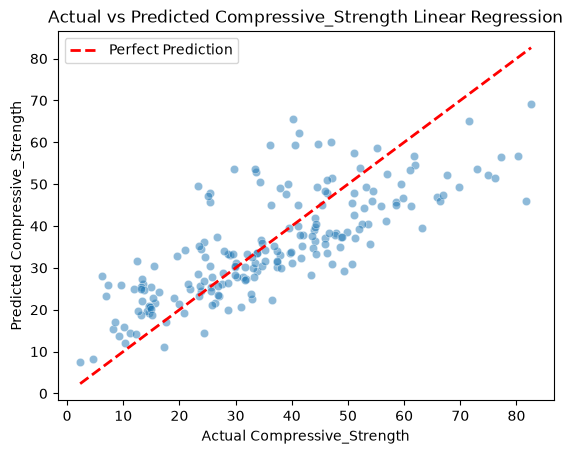

In [23]:
sns.scatterplot(x=y_test, y=predicted_test, alpha=.5);
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction');
plt.title("Actual vs Predicted Compressive_Strength Linear Regression");
plt.xlabel("Actual Compressive_Strength"); 
plt.ylabel("Predicted Compressive_Strength"); 
plt.legend(); 
plt.show()


## 7. Modèle 2 : Régression polynomiale
On garde un modèle linéaire, mais on lui fournit des variables supplémentaires : les **carrés** de chaque variable et les **produits** de toutes les paires (par exemple `Age × W_C`, `Cement²`). Le modèle peut ainsi représenter des courbures et des interactions, tout en restant une combinaison linéaire.

Le pipeline enchaîne quatre étapes :

| Étape | Rôle |
|---|---|
| `ColumnTransformer` + `FunctionTransformer(np.log1p)` | remplace `Age` par $\log(1 + Age)$, les autres colonnes passent telles quelles (`remainder="passthrough"`). La résistance croît à peu près comme le logarithme de l'âge : la relation devient presque linéaire. |
| `PolynomialFeatures(degree=2, include_bias=False)` | crée les carrés et les produits deux à deux : 9 variables → **54 variables**. `include_bias=False` évite une colonne constante, puisque Ridge ajuste déjà une ordonnée à l'origine. |
| `StandardScaler()` | normalise **après** l'expansion : `Coarse_Aggregate²` vaut ~1 000 000 alors que `Age²` reste petit. Sans normalisation, la régularisation pénaliserait les coefficients de façon inégale. |
| `RidgeCV(alphas=np.logspace(-3, 3, 20))` | régression linéaire avec pénalité L2 sur les coefficients, qui stabilise le modèle face aux variables polynomiales très corrélées entre elles (`Cement` et `Cement²`…). La force de la pénalité `alpha` est choisie automatiquement par validation croisée parmi 20 valeurs de 0,001 à 1 000. |

Tout est dans un pipeline : les transformations sont apprises **uniquement sur `x_train`**, puis réappliquées telles quelles à `x_test` (pas de fuite de données).

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
import numpy as np

pre = ColumnTransformer([
    ("log_age", FunctionTransformer(np.log1p), ["Age"]),
], remainder="passthrough")

modelPoly = make_pipeline(
    pre,
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),                         # scale AFTER expanding
    RidgeCV(alphas=np.logspace(-3, 3, 20)),   # regularisation picks itself via CV
)
modelPoly.fit(x_train, y_train)

predictedPoly_train = modelPoly.predict(x_train)

predictedPoly_test = modelPoly.predict(x_test)

print(pd.DataFrame({'Actual_train': y_train, 'Predicted_train': predictedPoly_train}).head(10).round(2))
print(pd.DataFrame({'Actual_test': y_test, 'Predicted_test': predictedPoly_test}).head(10).round(2))

     Actual_train  Predicted_train
78          41.30            35.49
29          38.60            33.91
280         23.14            19.29
507         23.85            40.54
652         15.75            17.51
946         44.52            50.97
289         52.04            49.45
165         10.38             8.22
761         16.26            20.16
497         24.13            24.80
     Actual_test  Predicted_test
926        19.01           25.37
630        24.29           24.88
682        26.32           21.40
514        34.57           37.51
365        44.13           42.38
655        33.00           30.95
656        17.28           18.34
529        25.42           24.05
321        33.73           36.49
70         34.40           34.75


### Évaluation de la régression polynomiale

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('---------------- Train dataset -----------------------')
print('MAE train:', mean_absolute_error(y_train, predictedPoly_train).__round__(2))
print('MSE train:', mean_squared_error(y_train, predictedPoly_train).__round__(2))
print('R-Squared train:', r2_score(y_train, predictedPoly_train).__round__(2))

print('---------------- Test dataset -----------------------')
print('MAE test:', mean_absolute_error(y_test, predictedPoly_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predictedPoly_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predictedPoly_test).__round__(2))

---------------- Train dataset -----------------------
MAE train: 4.01
MSE train: 27.16
R-Squared train: 0.89
---------------- Test dataset -----------------------
MAE test: 4.46
MSE test: 37.64
R-Squared test: 0.87


**Résultats :** R² ≈ 0,89 (train) et 0,87 (test), MAE test ≈ 4,5 MPa.
- C'est un **énorme progrès** par rapport à la régression linéaire : l'erreur moyenne est divisée par deux (8,8 → 4,5 MPa), et le R² test passe de 0,58 à 0,87.
- L'écart train / test reste faible : pas de surapprentissage, malgré 54 variables pour 804 mélanges.
- `RidgeCV` a retenu `alpha = 0,001`, la plus petite valeur proposée : le modèle n'a presque pas besoin de régularisation. On pourrait essayer un degré 3, plus flexible, où la régularisation deviendrait utile.
- Il reste un biais pour les bétons les plus résistants (> 47 MPa), sous-estimés de ≈ 6 MPa en moyenne, contre ≈ 12 MPa pour la régression linéaire.

## 8. Modèle 3 : Random Forest
Une forêt aléatoire combine de nombreux arbres de décision, chacun entraîné sur un échantillon aléatoire des données ; la prédiction finale est la moyenne des arbres. Elle capture naturellement les effets non linéaires (plafonnement avec l'âge) et les interactions, **sans normalisation** ni transformation des variables.

Hyperparamètres utilisés :
- `n_estimators=500` : nombre d'arbres. Ajouter des arbres ne cause jamais de surapprentissage, cela stabilise seulement les prédictions (au prix du temps de calcul) ;
- `max_depth=None` : les arbres poussent jusqu'au bout. Chaque arbre seul surapprend, mais la moyenne de 500 arbres différents compense ;
- `min_samples_split=2` : nombre minimal d'échantillons pour diviser un nœud ;
- `min_samples_leaf=2` : au moins 2 mélanges par feuille, ce qui lisse légèrement les prédictions ;
- `max_features=0.6` : à chaque coupure, l'arbre ne choisit que parmi 60 % des variables (5 sur 9), tirées au hasard. Les arbres se ressemblent moins, ce qui rend leur moyenne plus efficace ;
- `oob_score=True` : chaque arbre ignore environ un tiers des mélanges d'entraînement ; ces mélanges « hors du sac » (*out-of-bag*) servent à calculer un score de validation gratuit, disponible dans `modelRandomForest.oob_score_` (≈ **0,90** ici) ;
- `n_jobs=-1` : utilise tous les cœurs du processeur ;
- `random_state=42` : reproductibilité.

In [26]:
from sklearn.ensemble import RandomForestRegressor
modelRandomForest = RandomForestRegressor(n_estimators=500, max_depth=None, min_samples_split=2, min_samples_leaf=2, oob_score=True, max_features=0.6, n_jobs=-1, random_state=42)


modelRandomForest.fit(x_train, y_train)
predictedRf_train = modelRandomForest.predict(x_train)

predictedRf_test = modelRandomForest.predict(x_test)

print(pd.DataFrame({'Actual_train': y_train, 'Predicted_train': predictedRf_train}).head(10).round(2))
print(pd.DataFrame({'Actual_test': y_test, 'Predicted_test': predictedRf_test}).head(10).round(2))

     Actual_train  Predicted_train
78          41.30            39.35
29          38.60            34.41
280         23.14            23.19
507         23.85            33.66
652         15.75            15.15
946         44.52            51.14
289         52.04            49.77
165         10.38            10.27
761         16.26            16.02
497         24.13            20.82
     Actual_test  Predicted_test
926        19.01           23.04
630        24.29           26.46
682        26.32           25.77
514        34.57           35.22
365        44.13           48.19
655        33.00           32.60
656        17.28           24.14
529        25.42           22.65
321        33.73           32.72
70         34.40           34.33


### Évaluation de la Random Forest

In [27]:
print('---------------- Train dataset -----------------------')
print('MAE train:', mean_absolute_error(y_train, predictedRf_train).__round__(2))
print('MSE train:', mean_squared_error(y_train, predictedRf_train).__round__(2))
print('R-Squared train:', r2_score(y_train, predictedRf_train).__round__(2))

print('---------------- Test dataset -----------------------')
print('MAE test:', mean_absolute_error(y_test, predictedRf_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predictedRf_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predictedRf_test).__round__(2))

---------------- Train dataset -----------------------
MAE train: 1.89
MSE train: 7.39
R-Squared train: 0.97
---------------- Test dataset -----------------------
MAE test: 3.75
MSE test: 27.7
R-Squared test: 0.91


**Résultats :** R² ≈ 0,97 (train) et 0,91 (test), MAE test ≈ 3,75 MPa.
- Meilleur que la régression polynomiale (MAE 4,5 → 3,75 MPa).
- L'écart train / test (0,97 contre 0,91) est **normal pour une Random Forest** aux arbres profonds : chaque arbre connaît bien ses données d'entraînement. Ce qui compte est le score sur des données nouvelles, et le score *out-of-bag* (≈ 0,90) confirme le score de test.

### Importance des variables
La Random Forest construit ses arbres en coupant les données en deux à chaque étape (par exemple `Age <= 21` ou `W_C <= 0,6`), et chaque coupure fait baisser l'erreur. `feature_importances_` donne, pour chaque variable, la **part de cette baisse d'erreur** obtenue grâce à elle, sur l'ensemble des arbres. Le total des importances vaut 1.

Le graphique trie les variables par importance. La valeur n'est affichée que pour celles qui dépassent 1 %.

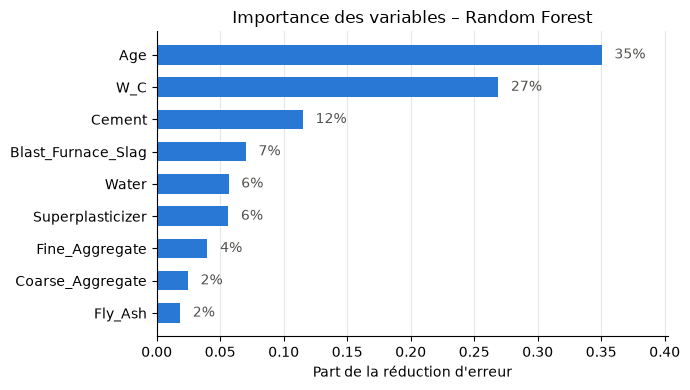

In [28]:
importances = pd.Series(modelRandomForest.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importances.index, importances.values, color='#2a78d6', height=0.6)

# Valeur affichée au bout des barres, uniquement pour les variables qui comptent (≥ 1 %)
for i, v in enumerate(importances.values):
    if v >= 0.01:
        ax.text(v + 0.01, i, f"{v:.0%}", va='center', color='#52514e')

ax.set_title("Importance des variables – Random Forest")
ax.set_xlabel("Part de la réduction d'erreur")
ax.set_xlim(0, importances.max() * 1.15)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


**Lecture :**

| Variable | Importance |
|---|---|
| `Age` | ≈ 35 % |
| `W_C` | ≈ 27 % |
| `Cement` | ≈ 12 % |
| `Blast_Furnace_Slag` | ≈ 7 % |
| `Water`, `Superplasticizer` | ≈ 6 % chacune |
| `Fine_Aggregate`, `Coarse_Aggregate`, `Fly_Ash` | ≈ 2 à 4 % |

- L'**âge** est la variable la plus utilisée, alors que sa corrélation linéaire (+0,34) était plus faible que celle du ciment : la forêt exploite sa relation non linéaire (forte hausse jusqu'à 28 jours, puis plateau), que la corrélation de Pearson ne mesure pas.
- Le **rapport eau / ciment** arrive en deuxième position, loin devant `Water` et `Cement` pris séparément : la variable construite résume mieux l'information que les deux colonnes d'origine.
- `Cement` paraît moins important qu'attendu, car `W_C` porte déjà une grande partie de son information (corrélation −0,88) : les deux variables se « partagent » l'importance.

> 💡 **Limites :** cette importance est calculée sur les données d'entraînement et favorise les variables qui ont beaucoup de valeurs différentes. L'importance par permutation (`sklearn.inspection.permutation_importance`), calculée sur le jeu de test, est plus fiable : elle mesure de combien le score baisse quand on mélange une colonne. Elle donne ici le même trio de tête (`Age` > `W_C`, puis `Blast_Furnace_Slag` et `Cement`).

## 9. Modèle 4 : Réseau de neurones (MLP)

### Prétraitement
Un réseau de neurones, entraîné par descente de gradient, converge mal quand les variables ont des échelles très différentes. Le pipeline prépare donc les données en trois points :
- `Age` passe par `np.log1p` (pour la même raison que la régression polynomiale), **puis** par un `StandardScaler` ;
- toutes les autres colonnes passent par un `StandardScaler` (`remainder=StandardScaler()`), qui les ramène à une moyenne de 0 et un écart-type de 1 ;
- la **cible** est elle aussi normalisée grâce à `TransformedTargetRegressor` : le réseau apprend à prédire une résistance normalisée, puis la prédiction est automatiquement reconvertie en MPa. Une cible centrée autour de 0 rend l'apprentissage plus stable.

Comme pour les autres modèles, toutes les transformations sont apprises **uniquement sur `x_train`** (pas de fuite de données).

### Le modèle
Le `MLPRegressor` est un réseau de neurones entièrement connecté :
- `hidden_layer_sizes=(128, 64)` : 2 couches cachées de 128 puis 64 neurones. Avec ~800 mélanges, deux couches suffisent ; un réseau plus profond serait plus difficile à entraîner sans gain de précision ;
- `activation='relu'` : fonction d'activation ReLU ;
- `solver='adam'`, `learning_rate_init=0.001` : algorithme d'optimisation et taille des pas d'apprentissage ;
- `alpha=0.0001` : régularisation L2 (pénalité sur la taille des poids), ici faible. Une valeur 10 fois plus forte a été testée sans gain (voir les résultats plus bas) ;
- `batch_size=32` : les poids sont mis à jour tous les 32 mélanges. De petits lots donnent plus de mises à jour par passage et généralisent souvent mieux sur un petit jeu de données ;
- `max_iter=5000` : limite haute du nombre de passages sur les données (non atteinte grâce à l'arrêt anticipé) ;
- `random_state=42` : reproductibilité de l'initialisation des poids et du choix des données de validation.

### Arrêt anticipé (`early_stopping=True`)
1. 10 % du jeu d'entraînement est mis de côté comme **jeu de validation** (`validation_fraction=0.1`) ;
2. après chaque passage sur les données, le R² est calculé sur ce jeu de validation ;
3. si ce score ne progresse plus pendant **50 passages consécutifs** (`n_iter_no_change=50`), l'entraînement s'arrête et le réseau garde les poids du meilleur passage.

La valeur par défaut (10) est trop impatiente sur un petit jeu de données, où le score de validation fluctue beaucoup. Ici, l'entraînement s'arrête après **252 passages**, avec un R² de validation d'environ 0,94.

In [29]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer
from sklearn.pipeline import make_pipeline
import numpy as np


pre = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["Age"]),
], remainder=StandardScaler())

mlp = MLPRegressor(hidden_layer_sizes=(128,64), activation='relu', solver='adam', alpha=0.0001, learning_rate_init=0.001, batch_size=32, max_iter=5000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=50, random_state=42)
modelMLP = TransformedTargetRegressor(
    regressor = make_pipeline(pre, mlp),
    transformer = StandardScaler(),
)

modelMLP.fit(x_train, y_train)
predictedMLP_train = modelMLP.predict(x_train)

predictedMLP_test = modelMLP.predict(x_test)

print(pd.DataFrame({'Actual_train': y_train, 'Predicted_train': predictedMLP_train}).head(10).round(2))
print(pd.DataFrame({'Actual_test': y_test, 'Predicted_test': predictedMLP_test}).head(10).round(2))

     Actual_train  Predicted_train
78          41.30            42.10
29          38.60            40.41
280         23.14            21.53
507         23.85            24.46
652         15.75            15.82
946         44.52            45.56
289         52.04            50.58
165         10.38            11.34
761         16.26            17.86
497         24.13            22.35
     Actual_test  Predicted_test
926        19.01           20.32
630        24.29           25.86
682        26.32           27.03
514        34.57           31.36
365        44.13           43.16
655        33.00           31.55
656        17.28           18.48
529        25.42           23.73
321        33.73           33.60
70         34.40           30.42


### Évaluation du MLP

In [30]:
print('---------------- Train dataset -----------------------')
print('MAE train:', mean_absolute_error(y_train, predictedMLP_train).__round__(2))
print('MSE train:', mean_squared_error(y_train, predictedMLP_train).__round__(2))
print('R-Squared train:', r2_score(y_train, predictedMLP_train).__round__(2))

print('---------------- Test dataset -----------------------')
print('MAE test:', mean_absolute_error(y_test, predictedMLP_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predictedMLP_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predictedMLP_test).__round__(2))

---------------- Train dataset -----------------------
MAE train: 1.36
MSE train: 4.89
R-Squared train: 0.98
---------------- Test dataset -----------------------
MAE test: 2.78
MSE test: 20.81
R-Squared test: 0.93


**Résultats :** R² ≈ 0,98 (train) et 0,93 (test), MAE test ≈ 2,8 MPa. C'est le **meilleur modèle** sur le jeu de test.
- L'écart train / test (0,98 contre 0,93) indique un **léger surapprentissage**, plus marqué que pour les autres modèles.

**Test d'une régularisation plus forte (`alpha`)** – même découpage, mêmes autres réglages :

| `alpha` | R² train | R² test | MAE test | R² validation croisée (5 plis) | Itérations |
|---|---|---|---|---|---|
| 0,0001 (retenu) | 0,98 | **0,930** | **2,78 MPa** | **0,924 ± 0,007** | 252 |
| 0,001 | 0,98 | 0,924 | 2,87 MPa | 0,920 ± 0,006 | 263 |

- Multiplier `alpha` par 10 **ne réduit pas** l'écart train / test et dégrade légèrement le score de test. On garde donc `alpha=0.0001`.
- La différence entre les deux réglages (0,004 en validation croisée) est plus petite que la variation d'un découpage à l'autre (≈ 0,006) : les deux sont en pratique équivalents.
- La régularisation `alpha` n'est donc pas ce qui limite le modèle. L'écart train / test vient surtout du **bruit de mesure** (voir la section 2) : le réseau en apprend une partie sur l'entraînement, et ce bruit n'est par nature pas prévisible sur le test. L'arrêt anticipé joue déjà le rôle de régularisation.
- Contrairement aux autres modèles, le MLP n'a presque plus de biais pour les bétons les plus résistants (> 47 MPa) : ils ne sont sous-estimés que de ≈ 2 MPa en moyenne, contre ≈ 5 MPa pour la Random Forest et ≈ 12 MPa pour la régression linéaire.

## 10. Comparaison et conclusion

| Modèle | MAE test (MPa) | R² train | R² test | R² validation croisée (5 plis) | Écart train / test |
|---|---|---|---|---|---|
| Régression linéaire | ≈ 8,83 | 0,61 | 0,58 | 0,59 ± 0,03 | aucun (sous-apprentissage) |
| Régression polynomiale (degré 2, Ridge) | ≈ 4,46 | 0,89 | 0,87 | 0,87 ± 0,00 | faible |
| Random Forest | ≈ 3,75 | 0,97 | 0,91 | 0,91 ± 0,01 | normal pour une forêt |
| MLP (128, 64) | **≈ 2,78** | 0,98 | **0,93** | **0,92 ± 0,01** | léger surapprentissage |

La validation croisée (5 découpages différents des 1 005 mélanges, calculée en dehors de ce notebook avec les mêmes réglages) confirme le classement obtenu sur le jeu de test, avec des écarts-types faibles : les différences entre les modèles sont réelles et ne dépendent pas d'un découpage chanceux.

**Conclusions :**
- Le **MLP** est le meilleur modèle (R² test 0,93, erreur moyenne ≈ 2,8 MPa), suivi de près par la **Random Forest** (0,91, ≈ 3,75 MPa). Les deux capturent les effets non linéaires et les interactions entre ingrédients.
- La **régression polynomiale** montre qu'ajouter des carrés, des produits et `log(Age)` suffit à faire passer un modèle linéaire de 0,58 à 0,87 de R² : la non-linéarité est le cœur du problème.
- La **régression linéaire** sert de référence : simple et interprétable, mais elle ne peut pas représenter le plafonnement de la résistance avec l'âge.
- L'**âge** et le **rapport eau / ciment** sont les deux facteurs les plus déterminants de la résistance, devant le ciment, le laitier, l'eau et le superplastifiant. Les granulats et les cendres volantes ont un effet faible.
- La variable construite `W_C` améliore légèrement les modèles non linéaires (R² test de la Random Forest : 0,90 sans `W_C`, 0,91 avec ; MLP : 0,92 → 0,93) et rend surtout les modèles plus faciles à interpréter.

**Pistes d'amélioration :**
- Ajouter d'autres variables issues du génie civil : liant total `Cement + Blast_Furnace_Slag + Fly_Ash` et rapport eau / liant, puisque le laitier et les cendres volantes remplacent une partie du ciment ;
- Optimiser les hyperparamètres de la Random Forest et du MLP par validation croisée (`RandomizedSearchCV`). Pour le MLP, `alpha` semble peu influent (voir la section 9) : la taille des couches et `learning_rate_init` sont des pistes plus prometteuses ;
- Essayer le **Gradient Boosting** (`HistGradientBoostingRegressor`, XGBoost, LightGBM), souvent le plus performant sur ce type de données tabulaires.